# Clinical indices - testing the definitions on real recordings

The preprocessing (notebook 05) and the PEEP trial segmentation (notebook 06) give, for every recording, the breaths,
the lung mask, the regions and, for a PEEP trial, the breaths analysed in each step with their driving pressure. This
notebook chooses how to compute the clinical indices from them (layer 3).

What I want in this first version (decided on 2026-10-31):

- **for each breath**: EELI, TIV (global and regional), share of ventilation by region, global inhomogeneity (GI),
  centre of ventilation (ventro-dorsal and right-left), compliance (global and regional);
- **for each PEEP step**: the same indices on the analysed breaths, and the changes between steps of EELI, compliance,
  collapse and overdistension (Costa method), in a form that can be compared between patients;
- left for later: silent spaces, regional ventilation delay, oesophageal and transpulmonary pressure. Strain is not
  possible with EIT alone: it needs an absolute end-expiratory lung volume.

| § | Question |
|---|----------|
| 1 | How do I read EELI and TIV of a breath? |
| 2 | How do I describe the distribution of ventilation? |
| 3 | How do I compute compliance? |
| 4 | PEEP trials: what changes between steps, and the Costa method |
| 5 | Decisions |

The recordings are not in the repository. EIT values are in arbitrary units; pressures in mbar (1 mbar = 1.02 cmH2O).

*Research use only - not a medical device.*

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess
from fasteit.segmentation import segment_peep_trial

TEST_FILES = Path("../src/fasteit/test_files")
TIDAL_FILES = sorted(p for p in TEST_FILES.glob("*.bin") if "PEEP_trial" not in p.name)
TRIAL_FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))

BLUE, ORANGE, GREEN, GREY, INK = "#3987e5", "#e8730c", "#2a9d6f", "#9a9a9a", "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})

tidal = {p.stem: preprocess(load_data(p)) for p in TIDAL_FILES}
trials = {p.stem.replace("PEEP_trial_", ""): segment_peep_trial(preprocess(load_data(p))) for p in TRIAL_FILES}
print(len(tidal), "tidal recordings,", len(trials), "PEEP trials")

11 tidal recordings, 4 PEEP trials


## 1. How do I read EELI and TIV of a breath?

Following TREND (Frerichs et al., Thorax 2017, DOI: 10.1136/thoraxjnl-2016-208357), on the global signal inside the
lung mask:

- **EELI** = the signal at the end-expiratory valley. I take the valley at the **start** of the breath, the end of the
  previous expiration: the same moment as the PEEP of the breath (notebook 06). eitprocessing takes the valley at the
  end of the breath, i.e. the start of the next one.
- **TIV** = the signal at the peak minus the signal at the start of the breath (the "inspiratory" TIV, the default of
  eitprocessing).

First check: on the breaths that eitprocessing (v1.8.8, `EELI`, `TIV`) finds identical to ours, the values must be the
same.

In [2]:
def level_at(values, frames, fs, half_seconds):
    """Mean of `values` (time on axis 0) in +/- half_seconds around each frame (one sample if 0)."""
    h = int(round(half_seconds * fs))
    return np.array([values[max(0, f - h) : f + h + 1].mean(axis=0) for f in frames])


def eeli_tiv(rec, half_seconds):
    b = rec.breaths
    start = level_at(rec.global_signal, b.start_idx.to_numpy(), rec.fs, half_seconds)
    peak = level_at(rec.global_signal, b.peak_idx.to_numpy(), rec.fs, half_seconds)
    end = level_at(rec.global_signal, b.end_idx.to_numpy(), rec.fs, half_seconds)
    return pd.DataFrame({"eeli_start": start, "eeli_end": end, "tiv": peak - start})

In [3]:
from eitprocessing.datahandling.continuousdata import ContinuousData
from eitprocessing.features.breath_detection import BreathDetection
from eitprocessing.parameters.eeli import EELI
from eitprocessing.parameters.tidal_impedance_variation import TIV

rows = []
for name, rec in list(tidal.items()) + [(n, t.recording) for n, t in trials.items()]:
    signal = ContinuousData(label="global", name="global", unit="a.u.", category="impedance",
                            time=np.asarray(rec.time), values=np.asarray(rec.global_signal), sample_frequency=rec.fs)
    ref_eeli = EELI().compute_parameter(signal)
    ref_tiv = TIV().compute_continuous_parameter(signal, tiv_method="inspiratory")
    ours = eeli_tiv(rec, 0.0)
    b = rec.breaths
    # eitprocessing finds its own breaths on this signal: compare the breaths with the same start, peak and end
    theirs = {(round(x.start_time, 3), round(x.middle_time, 3), round(x.end_time, 3)): i
              for i, x in enumerate(BreathDetection().find_breaths(signal).values)}
    eeli_by_end = dict(zip(np.round(ref_eeli.time, 3), ref_eeli.values))
    diffs, same = [], 0
    for i, key in enumerate(zip(np.round(b.start_time, 3), np.round(b.peak_time, 3), np.round(b.end_time, 3))):
        if key in theirs:
            same += 1
            diffs += [abs(ref_tiv.values[theirs[key]] - ours.tiv[i]), abs(eeli_by_end[key[2]] - ours.eeli_end[i])]
    rows.append({"recording": name, "breaths": len(b), "same breaths": same,
                 "max difference": max(diffs) if diffs else np.nan})
pd.DataFrame(rows).set_index("recording")

,breaths,same breaths,max difference
recording,,,
01_Healthy_Lung_01,9,8,0.0
patient01_rec02,14,7,0.0
patient01_rec03,55,29,0.0
patient01_rec04,117,53,0.0
patient01_rec05,104,76,0.0
patient01_rec07,100,73,0.0
patient01_rec09,68,26,0.0
patient01_rec11,89,16,0.0
patient01_rec12,88,42,0.0


Where the breaths are the same the values are identical. But often they are not the same: eitprocessing searches
the valleys and peaks on the signal inside the lung mask, while fastEIT finds the breaths on the sum of all pixels
(the mask needs the breaths, notebook 05). How much does the timing matter for the TIV inside the mask? I move each
valley and peak to the extremum of the in-mask signal within 0.3 s and compare:

In [4]:
rows = []
for name, rec in list(tidal.items()) + [(n, t.recording) for n, t in trials.items()]:
    g, fs = np.asarray(rec.global_signal), rec.fs
    b = rec.breaths[rec.breaths.is_valid]
    w = int(round(0.3 * fs))
    s, p = b.start_idx.to_numpy(), b.peak_idx.to_numpy()
    s_own = np.array([max(0, x - w) + np.argmin(g[max(0, x - w) : x + w + 1]) for x in s])
    p_own = np.array([max(0, x - w) + np.argmax(g[max(0, x - w) : x + w + 1]) for x in p])
    ratio = (g[p] - g[s]) / (g[p_own] - g[s_own]) - 1
    rows.append({"recording": name, "valley shift (frames, max)": np.abs(s_own - s).max(),
                 "TIV difference (%, median)": 100 * np.median(ratio), "TIV difference (%, worst)": 100 * ratio.min()})
pd.DataFrame(rows).set_index("recording").round(2)

,"valley shift (frames, max)","TIV difference (%, median)","TIV difference (%, worst)"
recording,,,
01_Healthy_Lung_01,0,0.00,-0.02
patient01_rec02,2,0.00,-0.14
patient01_rec03,5,0.00,-1.82
patient01_rec04,3,0.00,-1.71
patient01_rec05,2,0.00,-0.09
patient01_rec07,1,0.00,-0.03
patient01_rec09,2,0.00,-2.27
patient01_rec11,3,-0.05,-0.41
patient01_rec12,2,0.00,-1.20


The valleys move by 0-5 frames, and the TIV with the fastEIT timing differs by 0 to -0.4 % in median (worst breath
-2.3 %). I keep the breath timing of layer 2 for every index.

Last question: one sample or a short mean? The physics review suggested a mean of 0.2 s around start and peak, so that
a cardiac oscillation does not fall on a single sample.

In [5]:
def variability(values):
    """Median breath-to-breath change, as % of the median value."""
    return 100 * np.median(np.abs(np.diff(values))) / np.median(np.abs(values))


rows = []
for name, rec in tidal.items():
    valid = rec.breaths.is_valid.to_numpy()
    one, window = eeli_tiv(rec, 0.0)[valid], eeli_tiv(rec, 0.1)[valid]
    rows.append({"recording": name,
                 "TIV, one sample": variability(one.tiv), "TIV, 0.2 s": variability(window.tiv),
                 "mean TIV difference (%)": 100 * (window.tiv.mean() / one.tiv.mean() - 1)})
pd.DataFrame(rows).set_index("recording").round(2).rename_axis("breath-to-breath change (% of median)", axis=1)

breath-to-breath change (% of median),"TIV, one sample","TIV, 0.2 s",mean TIV difference (%)
recording,,,
01_Healthy_Lung_01,9.83,9.83,-0.49
patient01_rec02,13.81,14.33,-2.00
patient01_rec03,9.21,9.12,-2.07
patient01_rec04,4.40,4.32,-2.33
patient01_rec05,8.14,8.03,-1.80
patient01_rec07,9.49,9.37,-2.07
patient01_rec09,8.38,8.05,-2.05
patient01_rec11,8.65,9.02,-2.60
patient01_rec12,10.66,11.00,-3.89


The mean does not make the TIV more stable from breath to breath, but it lowers it by 0.5-3.9 %: averaging around
a peak lowers the peak, averaging around a valley raises the valley. The cardiac component is small in these Dräger
exports (notebook 05), so there is nothing to average away. **One sample**, as TREND and eitprocessing.

## 2. How do I describe the distribution of ventilation?

All from the **tidal image** of each breath: each pixel at the peak minus at the start, inside the lung mask.

- **Share by region**: TIV of the region / TIV of the lung, as a ratio of the sums (a mean of pixel ratios explodes for
  pixels near zero). Regions of notebook 05: ventral/dorsal halves and layers on the lung, right/left halves.
- **GI** (Zhao et al., Intensive Care Med 2009, DOI: 10.1007/s00134-009-1589-y): sum of |pixel - median| / sum of
  pixels, over the lung pixels.
- **Centre of ventilation** (Frerichs et al., Am J Respir Crit Care Med 2006, DOI: 10.1164/rccm.200512-1942OC):
  TIV-weighted mean row (and column), divided by the last row (column). On the **image grid**, not on the regions of
  the lung, so that a shift of ventilation is not hidden (notebook 05). Ventro-dorsal: 0 = ventral, 1 = dorsal.
  Right-left: **0 = patient right, 1 = patient left** (image seen from the feet).

In [6]:
def tidal_images(rec):
    """Pixel TIV of each breath: (n_breaths, rows, cols), NaN outside the lung mask."""
    b = rec.breaths
    images = (rec.pixels[b.peak_idx.to_numpy()] - rec.pixels[b.start_idx.to_numpy()]).astype(float)
    images[:, ~rec.lung_mask] = np.nan
    return images


def gi(image):
    """Global inhomogeneity index (Zhao 2009) of one tidal image (lung pixels only)."""
    lung = image[~np.isnan(image)]
    return np.abs(lung - np.median(lung)).sum() / lung.sum()


def centre_of_ventilation(image):
    """(ventro-dorsal, right-left): 0 = ventral / patient right, 1 = dorsal / patient left."""
    tiv = np.nan_to_num(image)
    rows, cols = np.indices(tiv.shape)
    return ((tiv * rows).sum() / tiv.sum() / (tiv.shape[0] - 1),
            (tiv * cols).sum() / tiv.sum() / (tiv.shape[1] - 1))


def share(image, region):
    """% of the tidal ventilation in a region: ratio of the sums."""
    tiv = np.nan_to_num(image)
    return 100 * tiv[region].sum() / tiv.sum()


# Synthetic checks with a known answer.
flat = np.full((32, 32), np.nan)
flat[8:24, 4:28] = 1.0                              # homogeneous ventilation
dorsal = flat.copy()
dorsal[16:24] = 3.0                                 # three times more ventilation in the dorsal half
right = flat.copy()
right[:, 4:16] = 3.0                                # three times more in the patient's right lung (image left)
pd.DataFrame({name: {"GI": gi(img), "CoV ventro-dorsal": centre_of_ventilation(img)[0],
                     "CoV right-left": centre_of_ventilation(img)[1]}
              for name, img in [("homogeneous", flat), ("dorsal x3", dorsal), ("right x3", right)]}).T.round(3)

,GI,CoV ventro-dorsal,CoV right-left
homogeneous,0.000,0.500,0.500
dorsal x3,0.400,0.577,0.500
right x3,0.286,0.500,0.362


Homogeneous ventilation gives GI = 0 and the centre in the middle (0.5, 0.5); more dorsal ventilation moves the
ventro-dorsal centre towards 1, more ventilation in the patient's right lung moves the right-left centre towards 0.
On the tidal recordings (median of the valid breaths):

In [7]:
def breath_indices(rec):
    rows = []
    for image in tidal_images(rec):
        vd, rl = centre_of_ventilation(image)
        rows.append({"gi": gi(image), "cov_vd": vd, "cov_rl": rl,
                     **{f"share_{r}": share(image, rec.roi_masks[r]) for r in ("ventral", "dorsal", "right", "left")}})
    return pd.DataFrame(rows)


distribution = pd.DataFrame({name: breath_indices(rec)[rec.breaths.is_valid.to_numpy()].median()
                             for name, rec in tidal.items()}).T
distribution.round(3)

,gi,cov_vd,cov_rl,share_ventral,share_dorsal,share_right,share_left
01_Healthy_Lung_01,0.381,0.502,0.465,56.366,43.634,56.578,43.422
patient01_rec02,0.388,0.449,0.489,44.044,55.956,52.553,47.447
patient01_rec03,0.439,0.474,0.497,36.428,63.572,50.862,49.138
patient01_rec04,0.431,0.487,0.480,40.701,59.299,55.137,44.863
patient01_rec05,0.371,0.445,0.486,44.607,55.393,52.353,47.647
patient01_rec07,0.358,0.438,0.467,46.631,53.369,56.780,43.220
patient01_rec09,0.447,0.488,0.480,39.668,60.332,55.126,44.874
patient01_rec11,0.483,0.532,0.504,51.253,48.747,48.337,51.663
patient01_rec12,0.532,0.527,0.506,53.226,46.774,48.246,51.754
patient01_rec13,0.529,0.514,0.498,46.832,53.168,51.175,48.825


GI 0.36-0.53, ventro-dorsal centre 0.44-0.57, right-left centre 0.47-0.51, ventral share 36-56 %, right share
48-57 %: no recording stands out. eitprocessing has no GI or centre of ventilation to compare with, so these indices
rest on their published formulas and on the synthetic checks above.

Fixed halves of the image (question left open in notebook 05) are not needed: the centre of ventilation is already
computed on the image grid and shows a shift of ventilation that the regions on the lung would hide.

## 3. How do I compute compliance?

Compliance of a breath = TIV / driving pressure (plateau - PEEP, notebook 06), globally and for each region (TIV of
the region). Without the tidal volume it is in EIT units per mbar, not comparable between patients; **as % of its best
value in the trial** it is. Per step: median of the analysed breaths.

In [8]:
rows = []
for name, trial in trials.items():
    b = trial.breaths
    tiv = np.nansum(tidal_images(trial.recording), axis=(1, 2))
    compliance = tiv / b.driving_pressure.to_numpy()
    a = b.analysed.to_numpy()
    for k in range(len(trial.steps)):
        in_step = a & (b.peep_step.to_numpy() == k)
        rows.append({"trial": name, "step": k, "peep": trial.steps.peep[k],
                     "tiv": np.median(tiv[in_step]), "compliance": np.nanmedian(compliance[in_step])})
steps = pd.DataFrame(rows)
steps["compliance % of best"] = 100 * steps.compliance / steps.groupby("trial").compliance.transform("max")
steps.pivot(index="step", columns="trial", values="compliance % of best").round(0)

trial,A_park_bench,A_supine,B_park_bench,B_supine
step,,,,
0,87.0,78.0,94.0,94.0
1,92.0,83.0,94.0,100.0
2,95.0,88.0,93.0,100.0
3,98.0,94.0,94.0,97.0
4,100.0,94.0,95.0,87.0
5,99.0,100.0,98.0,76.0
6,98.0,95.0,100.0,65.0
7,99.0,90.0,94.0,56.0
8,96.0,81.0,87.0,48.0


The best global compliance is at PEEP 8 (A park bench), 6 (A supine), 4 (B park bench, almost flat between 87 and
100 %) and 14 (B supine, which keeps 100 % at 12.5 and then loses half of its compliance by PEEP 1).

## 4. PEEP trials: what changes between steps, and the Costa method

**Costa method** (Costa et al., Intensive Care Med 2009, DOI: 10.1007/s00134-009-1447-y; formulas as reported by Shono
and Kotani, J Intensive Care 2019, DOI: 10.1186/s40560-019-0358-4):

- compliance of each pixel at each step = pixel TIV / driving pressure (median of the analysed breaths);
- each pixel has its best compliance, at its best PEEP;
- at a step with a lower PEEP than its best, the loss of compliance of the pixel, as % of its best, is **collapse**; at a
  higher PEEP it is **overdistension**;
- collapse (and overdistension) of the step = mean of the pixel %, weighted by the best compliance of each pixel, over
  the pixels of the lung mask;
- the crossing of the two curves is the PEEP with the best balance between them.

Check on two synthetic pixels first: pixel 1 has its best compliance at PEEP 16 and loses half of it at 6; pixel 2 has
its best at 6 and three times the best compliance of pixel 1.

In [9]:
def costa_from_compliance(pixel_c, peep, valid):
    """Collapse and overdistension % per step from pixel compliance (steps, rows, cols)."""
    best = np.nanmax(pixel_c, axis=0)
    best_step = np.nanargmax(np.where(np.isnan(pixel_c), -np.inf, pixel_c), axis=0)
    valid = valid & (best > 0)
    loss = (best - pixel_c) / best * 100                       # % below the best, per pixel and step
    weight = best[valid].sum()
    collapse, overdistension = [], []
    for k in range(len(peep)):
        below = valid & (peep[k] < peep[best_step])           # lower PEEP than the pixel's best: collapse
        above = valid & (peep[k] > peep[best_step])           # higher PEEP than the pixel's best: overdistension
        collapse.append((loss[k][below] * best[below]).sum() / weight)
        overdistension.append((loss[k][above] * best[above]).sum() / weight)
    return pd.DataFrame({"peep": peep, "collapse": collapse, "overdistension": overdistension})


def crossing(table):
    """PEEP where the collapse and overdistension curves cross (linear interpolation)."""
    t = table.sort_values("peep")
    diff = (t.collapse - t.overdistension).to_numpy()
    for i in range(len(diff) - 1):
        if diff[i] >= 0 >= diff[i + 1]:
            p0, p1 = t.peep.iloc[i], t.peep.iloc[i + 1]
            return p0 + (p1 - p0) * diff[i] / (diff[i] - diff[i + 1])
    return np.nan


peep = np.array([16.0, 6.0])
pixel_c = np.array([[[1.0, 1.5]],                            # PEEP 16: pixel 1 at its best, pixel 2 at half of 3
                    [[0.5, 3.0]]])                           # PEEP 6: pixel 1 at half, pixel 2 at its best
costa_from_compliance(pixel_c, peep, np.ones((1, 2), dtype=bool)).round(1)

,peep,collapse,overdistension
0,16.0,0.0,37.5
1,6.0,12.5,0.0


At PEEP 6 pixel 1 lost 50 % (collapse) with weight 1 out of 4: 12.5 %. At PEEP 16 pixel 2 lost 50 %
(overdistension) with weight 3 out of 4: 37.5 %. On the four trials:

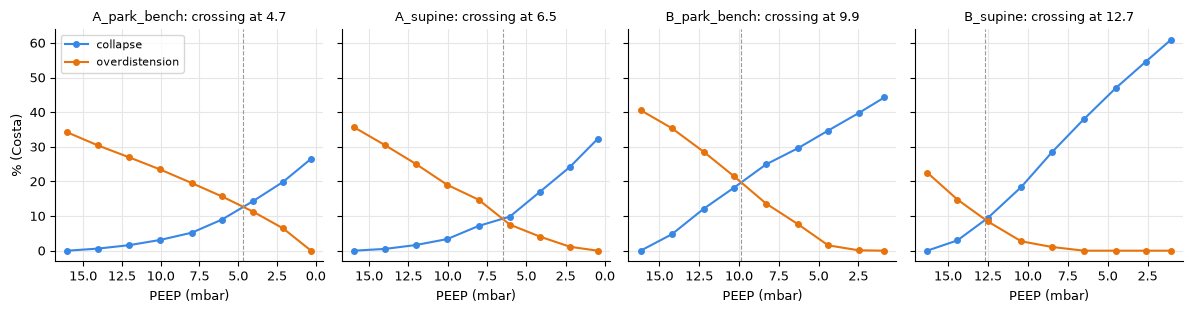

In [10]:
def costa(trial):
    b = trial.breaths
    images = tidal_images(trial.recording)
    a, step = b.analysed.to_numpy(), b.peep_step.to_numpy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # pixels outside the mask are all NaN
        pixel_c = np.array([np.nanmedian(images[a & (step == k)], axis=0) / trial.steps.driving_pressure[k]
                            for k in range(len(trial.steps))])
        return costa_from_compliance(pixel_c, trial.steps.peep.to_numpy(), trial.recording.lung_mask)


odcl = {name: costa(trial) for name, trial in trials.items()}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, table) in zip(axes, odcl.items()):
    ax.plot(table.peep, table.collapse, "o-", color=BLUE, ms=4, label="collapse")
    ax.plot(table.peep, table.overdistension, "o-", color=ORANGE, ms=4, label="overdistension")
    cross = crossing(table)
    ax.axvline(cross, color=GREY, lw=0.8, ls="--")
    ax.set_title(f"{name}: crossing at {cross:.1f}", fontsize=9)
    ax.set_xlabel("PEEP (mbar)")
    ax.invert_xaxis()
axes[0].set_ylabel("% (Costa)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
best_peep = steps.loc[steps.groupby("trial").compliance.idxmax(), ["trial", "peep"]].set_index("trial").peep
pd.DataFrame({"crossing PEEP": {n: crossing(t) for n, t in odcl.items()},
              "PEEP of the best global compliance": best_peep}).round(1)

,crossing PEEP,PEEP of the best global compliance
A_park_bench,4.7,8.0
A_supine,6.5,6.0
B_park_bench,9.9,4.4
B_supine,12.7,14.4


The curves have the expected shape: overdistension falls and collapse rises as PEEP is lowered. The crossings are
4.7 and 6.5 mbar in patient A, 9.9 and 12.7 in patient B; in both patients the crossing is lower in park bench than
supine (an observation on two patients). In A supine and B supine the crossing is close to the PEEP of the best global
compliance; in A park bench and B park bench, where compliance changes little across the steps, it is not.

### Changes between steps

For the statistics I need numbers that can be compared between patients. EELI in arbitrary units cannot, so I express
its change **in tidal volumes**: the change of EELI divided by the TIV (of the previous step, or of the first step for
the cumulative change). Compliance as % of its best, collapse and overdistension in %.

In [12]:
rows = []
for name, trial in trials.items():
    b, s = trial.breaths, trial.steps
    eeli = trial.recording.global_signal[b.start_idx.to_numpy()]
    tiv = np.nansum(tidal_images(trial.recording), axis=(1, 2))
    a, step = b.analysed.to_numpy(), b.peep_step.to_numpy()
    eeli_step = np.array([np.median(eeli[a & (step == k)]) for k in range(len(s))])
    tiv_step = np.array([np.median(tiv[a & (step == k)]) for k in range(len(s))])
    best = steps.query("trial == @name")["compliance % of best"].to_numpy()
    table = odcl[name]
    for k in range(1, len(s)):
        rows.append({"trial": name, "peep": round(s.peep[k], 1),
                     "dEELI in TIV (vs previous)": (eeli_step[k] - eeli_step[k - 1]) / tiv_step[k - 1],
                     "dEELI in TIV (vs first)": (eeli_step[k] - eeli_step[0]) / tiv_step[0],
                     "d compliance (% of best)": best[k] - best[k - 1],
                     "d collapse (%)": table.collapse[k] - table.collapse[k - 1],
                     "d overdistension (%)": table.overdistension[k] - table.overdistension[k - 1]})
deltas = pd.DataFrame(rows)
deltas.groupby("trial")[["dEELI in TIV (vs previous)", "dEELI in TIV (vs first)", "d compliance (% of best)",
                          "d collapse (%)", "d overdistension (%)"]].agg(["min", "max"]).round(2)

dEELI in TIV (vs previous)       dEELI in TIV (vs first)        \
                                    min   max                     min   max   
trial                                                                         
A_park_bench                      -0.59 -0.29                   -3.15 -0.29   
A_supine                          -0.63 -0.41                   -4.40 -0.41   
B_park_bench                      -0.64 -0.20                   -3.60 -0.20   
B_supine                          -0.47 -0.03                   -2.28 -0.35   

             d compliance (% of best)       d collapse (%)        \
                                  min   max            min   max   
trial                                                              
A_park_bench                    -2.77  5.12           0.60  6.68   
A_supine                        -9.19  5.61           0.52  8.04   
B_park_bench                    -6.74  2.49           4.48  7.39   
B_supine                       -10.98  5.82           2.97  9.98   

             d overdistension (%)        
                              min   max  
trial                                    
A_park_bench                -6.46 -3.47  
A_supine                    -7.20 -1.12  
B_park_bench                -7.82 -0.11  
B_supine                    -7.78  0.00

Each step of 2 mbar lowers EELI by 0.03-0.64 tidal volumes; by the last step the cumulative loss is 2.3-4.4 tidal
volumes. Per step, compliance changes by -11 to +6 % of its best, collapse rises by 0.5-10 % and overdistension falls by
0-8 %. These are numbers on a common scale, which can go into the same analysis for different patients (with the
limits below).

## 5. Decisions

Proposals from this notebook, to confirm:

1. **EELI and TIV** of a breath: one sample at the frames of the layer 2 breaths, on the global signal inside the lung
   mask; EELI at the start of the breath; TIV = peak - start. Identical to eitprocessing on the same breaths.
2. **Per breath**: TIV global and by region; share by region (ratio of sums); GI over the lung pixels; centre of
   ventilation on the image grid, ventro-dorsal (0 = ventral) and right-left (0 = patient right); compliance = TIV /
   driving pressure, global and by region.
3. **Per step of a PEEP trial**: medians of the analysed breaths; compliance also as % of the best step; Costa collapse
   and overdistension (%), weighted by the best compliance of each pixel, over the lung mask; crossing PEEP.
4. **Changes between steps** (for the statistics): EELI in tidal volumes (vs the previous step and vs the first),
   compliance in % of the best, collapse and overdistension in %; to choose: vs the previous step, the first, or both.
5. **Tidal recordings**: median and interquartile range of the per-breath indices over the valid breaths.

Limits: two patients, decremental trials only; Costa implemented from its published formulas and checked on synthetic
pixels, not against another implementation; compliance in EIT units per mbar (no tidal volume); one lung mask for the
whole trial.